# HW1 · Part 1. 사양에서 f 예측 — 2주차 (10점 · 예상 2–3시간)

**배포본:** v5 (2026-10-20)

**목표** — 카메라 사양(EXIF)만으로 K 를 예측하고, 그 K 가 어디까지 맞는지(거리 · 변환 규칙 · 이미지 삽입) 실제 사진으로 확인

**참고** — MVG 2판 §6.1 (핀홀 카메라 · K · P = K[R|t]), Zhang 2000 §2.2 · Appendix C (H = K[r₁ r₂ t] 와 (R, t) 복원), OpenCV 픽셀 좌표 규약

**TODO** — `f_px_from_exif` · `decompose_board_homography` · `K_after_resize_crop_rotate` · `warp_texture_onto_board` (4개)

**OpenCV 허용** — `cv2.findHomography`(H 추정은 5주차 범위), 1.3 검증용 `cv2.calibrateCamera`, `cv2.resize/rotate`, `cv2.undistortPoints`(1.4 의 역왜곡 좌표)

> **허용 · 금지** — NumPy · SciPy · Matplotlib 자유. OpenCV 는 각 Part 안내에 "허용" 으로 적힌 함수만(코너 검출 · `findHomography` · 검증용 비교). 
> `TODO` 로 표시된 함수를 OpenCV 호출로 대체하면 해당 항목 0점. 

In [1]:
# ---- 공통 설정 (HW1 v5 · 모든 노트북에서 같은 설정 파일 사용) ----
import os, sys, json, glob, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'hw1_config.json').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'hw1_config.json').is_file():
    raise FileNotFoundError('HW1 폴더 또는 notebooks 폴더에서 실행하세요: hw1_config.json 을 찾을 수 없습니다.')
sys.path.insert(0, str(ROOT))
from hw1lib import geometry as G, synth as S, exif as E, board as Bd, io_utils as IO, checks as CK, click_tool as CT
# 데모 전환은 HW1/hw1_config.json 의 mode 만 "demo" 로 변경하고 각 노트북의 이 셀을 다시 실행.
cfg = IO.load_config(ROOT)
DATA, RESULTS = cfg['DATA'], cfg['RESULTS']
IO.RESULTS = RESULTS
def load_corners_checked(name):
    """현재 설정과 저장 코너 파일의 검출 배율이 같은지 확인."""
    det = Bd.load_corners(IO.rpath(name))
    if not np.isclose(det['scale'], cfg['SCALE'], rtol=0, atol=1e-12):
        raise ValueError(f"{name}: 저장 배율 {det['scale']}과 현재 설정 scale={cfg['SCALE']}이 다릅니다. Part 0부터 다시 실행하세요.")
    return det
os.makedirs(RESULTS, exist_ok=True)
# 서로 다른 데이터의 결과를 같은 폴더에 섞지 않음. 상대 경로로 기록하여 제출 폴더 이동은 허용.
context = dict(mode=cfg['mode'], data=os.path.relpath(DATA, ROOT), version=5)
context_path = IO.rpath('dataset_context.json')
if os.path.exists(context_path):
    if IO.load_json(context_path) != context:
        raise ValueError('결과 폴더의 데이터 출처가 현재 설정과 다릅니다. 새 results 경로를 지정하고 Part 0부터 실행하세요.')
elif any(not p.name.startswith('.') for p in Path(RESULTS).iterdir()):
    raise ValueError('출처 기록이 없는 기존 결과가 있습니다. 새 results 경로를 지정하고 Part 0부터 실행하세요.')
IO.save_json(context_path, context)
np.set_printoptions(precision=4, suppress=True)
import matplotlib
_fonts = {f.name for f in matplotlib.font_manager.fontManager.ttflist}
for _f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Freesentation']:
    if _f in _fonts:
        matplotlib.rcParams['font.family'] = _f; break
matplotlib.rcParams['axes.unicode_minus'] = False
warnings.filterwarnings('ignore', message='Glyph')
%matplotlib inline
print('mode =', cfg['mode'], '\nDATA =', DATA, '\nRESULTS =', RESULTS)


mode = student 
DATA = /home/shw/3dvision/data 
RESULTS = /home/shw/3dvision/results


## 1.1 EXIF → f_px 예측 (3점)
EXIF 의 `FocalLength`(mm) 와 `FocalLengthIn35mmFilm`(35 mm 환산) 에서 픽셀 단위 초점거리를 예측합니다.
센서 실제 크기를 아는 경우(제조사 사양 · 데이터시트) 그 값으로도 계산해 비교하세요.

In [2]:
# ==============================================================================
# TODO  f_px_from_exif
# 참조: MVG 2판 §6.1 (카메라 모델 · K), 35 mm 환산 초점거리의 정의 (화각 보존)
# 35 mm 환산 초점거리 f35 는 "풀프레임(36 × 24 mm, 대각 43.27 mm) 센서에 같은 화각을 주는 초점거리" 라는 뜻
# → 화각이 같으려면 f35 / (풀프레임 크기) = f_px / (이미지 크기 px).  어느 "크기" 를 쓰느냐가 규약: 대각선(43.27 mm ↔ sqrt(W²+H²) px) 또는 가로(36 mm ↔ W px)
# 두 규약의 값이 다름(4:3 센서에서 수 %) → 둘 다 계산해 돌려주고, 보고서에서 어느 것을 택했는지 · 왜 다른지 쓸 것
# 실제 센서 크기 · 픽셀 피치를 아는 경우에는 f_px = f_mm / 픽셀피치(mm) 가 가장 직접적
# ==============================================================================
def f_px_from_exif(f35mm, width_px, height_px, sensor_aspect=(4, 3)):
    """35 mm 환산 초점거리 → 픽셀 단위 f.
    35 mm 풀프레임 대각선 43.27 mm 기준: f35/43.27 = f_px/diag_px (화각 보존)  (MVG §6.1)
    ※ 많은 폰이 '36 mm 가로 기준' 환산을 쓰므로 두 규약을 모두 돌려 보고 보고서에 어느 것을 택했는지 명시."""
    # ---- 여기에 작성 ----
    W, H = float(width_px), float(height_px)
    long_px = max(W, H)                                   # 가로 방향 사진 기준 긴 변 = 36 mm 에 대응
    f_diag = f35mm * np.hypot(W, H) / np.hypot(36.0, 24.0)   # 대각선 규약: 43.27 mm ↔ √(W² + H²) px
    f_horiz = f35mm * long_px / 36.0                      # 가로 규약: 36 mm ↔ W px
    return float(f_diag), float(f_horiz)


In [3]:
det = load_corners_checked('corners_setC.npz')
W, H = det['image_size']
ex = E.read_exif(os.path.join(DATA, 'setC', det['names'][0]))
print({k: ex[k] for k in ['Model', 'width', 'height', 'FocalLength', 'FocalLengthIn35mmFilm', 'DigitalZoomRatio']})
f35 = ex['FocalLengthIn35mmFilm']
f_diag, f_horiz = f_px_from_exif(f35, W, H)
print(f'35 mm 환산 {f35} mm → f_px (대각선 규약) = {f_diag:.1f},  (가로 36 mm 규약) = {f_horiz:.1f},  차이 {abs(f_diag-f_horiz)/f_diag*100:.1f} %')
# 센서 실제 크기를 아는 경우 (예: 픽셀 피치 1.4 µm, 비닝 2×2 → 유효 피치 2.8 µm): f_px = f_mm / pitch_mm
PIXEL_PITCH_UM = None      # 아는 경우 숫자(µm) 로 — 모르면 None
if PIXEL_PITCH_UM:
    print('센서 사양 기반 f_px =', ex['FocalLength'] / (PIXEL_PITCH_UM * 1e-3))
f_pred = f_diag                                     # ← 택한 규약 (보고서에 이유)
K_exif = G.make_K(f_pred, f_pred, (W - 1) / 2, (H - 1) / 2)   # 주점 = 이미지 중심 (픽셀 중심 규약)
IO.save_K('K_exif.json', K_exif, (W, H), 'exif', f_candidates=dict(diag=f_diag, horiz=f_horiz, f35mm=f35, FocalLength_mm=ex['FocalLength']))
K_exif

{'Model': 'Galaxy Z Flip8', 'width': 4000, 'height': 3000, 'FocalLength': 5.4, 'FocalLengthIn35mmFilm': 23, 'DigitalZoomRatio': 1.0}
35 mm 환산 23 mm → f_px (대각선 규약) = 2657.9,  (가로 36 mm 규약) = 2555.6,  차이 3.9 %


array([[2657.9384,    0.    , 1999.5   ],
       [   0.    , 2657.9384, 1499.5   ],
       [   0.    ,    0.    ,    1.    ]])

**보고서 질문 1.1** — 예측 f 가 틀릴 수 있는 요인 셋을 본인 기종 기준으로 (예: 환산 규약(대각/가로) · 센서 일부만 사용(비닝 · 화면비 크롭) · 디지털 줌 · 환산값 반올림 · AF 위치에 따른 f 변화).
Part 2 의 Zhang 결과와 비교했을 때 어느 요인이 가장 컸는지는 Part 6 에서 답합니다.

## 1.2 예측 K 로 보드까지 거리 (3점)
보드 한 장의 H (OpenCV `findHomography` 허용) 를 H = K[r₁ r₂ t] 로 분해 → 보드 중심의 카메라 좌표 → 거리 ‖X_c‖ 를 줄자 실측과 비교.
정면에 가깝고 광축 부근인 물체의 깊이는 초점거리 f에 거의 비례합니다. 기울어진 보드에서 자세까지 다시 추정한 중심의 유클리드 거리 ‖X_c‖는 정확히 같은 비율로 변하지 않을 수 있습니다.

In [4]:
# ==============================================================================
# TODO  decompose_board_homography
# 참조: Zhang 2000 §2.2 (H = K[r₁ r₂ t]) · §3.1 끝 (각 장의 R, t) · Appendix C (직교화), MVG Example 8.1
# H = μ K [r1 r2 t]  (μ 는 findHomography 가 정하는 임의 스케일) → K⁻¹H = μ [r1 r2 t]
# r1 이 단위 벡터여야 하므로 λ = 1 / ‖K⁻¹ h1‖  (h1 = H 의 첫 열).  r1 = λ K⁻¹ h1, r2 = λ K⁻¹ h2, t = λ K⁻¹ h3
# 부호: 보드는 카메라 앞에 있어야 하므로 t_z > 0.  음수면 H 전체의 부호를 뒤집음 (r1, r2, t 모두 −)
# r3 = r1 × r2.  잡음 때문에 [r1 r2 r3] 는 정확한 회전행렬이 아님 → SVD 로 가장 가까운 회전행렬 (Appendix C): Q = UΣVᵀ → R = UVᵀ  (geometry.nearest_rotation 사용 가능)
# 반환: (R (3×3), t (3,))  — X_c = R X_board + t
# ==============================================================================
def decompose_board_homography(K, H):
    """H ∼ K [r1 r2 t] 에서 (R, t) 복원 (Zhang §2.2 · §3.1 · Appendix C).
    λ = 1/‖K⁻¹h1‖, r1 = λK⁻¹h1, r2 = λK⁻¹h2, r3 = r1 × r2, t = λK⁻¹h3.  t_z < 0 이면 H 의 부호를 뒤집음.  R 은 SVD 로 직교화."""
    # ---- 여기에 작성 ----
    A = np.linalg.solve(np.asarray(K, float), np.asarray(H, float))   # K⁻¹ H = μ [r1 r2 t]
    lam = 1.0 / np.linalg.norm(A[:, 0])
    r1, r2, t = lam * A[:, 0], lam * A[:, 1], lam * A[:, 2]
    if t[2] < 0:                                          # 보드는 카메라 앞 (t_z > 0)
        r1, r2, t = -r1, -r2, -t
    R = G.nearest_rotation(np.column_stack([r1, r2, np.cross(r1, r2)]))   # Appendix C 직교화
    return R, t


In [5]:
import cv2
meas = IO.load_json(IO.rpath('measurements.json'))
name = meas['board_distance_image']
if name not in det['names']:
    raise ValueError(f'실측 사진 {name!r}의 코너가 없습니다. 파일명과 Part 0 검출 실패 목록을 확인하세요. 다른 사진의 실측값으로 대체하지 않습니다.')
i = det['names'].index(name)
X, m = det['objpoints'][i], det['imgpoints'][i]
Hm, _ = cv2.findHomography(X[:, :2], m)                      # 보드 (X, Y) mm → 픽셀
R, t = decompose_board_homography(K_exif, Hm)
center = np.array([(det['pattern'][0] - 1) * det['square'] / 2, (det['pattern'][1] - 1) * det['square'] / 2, 0.0])
Xc = R @ center + t
d_est = np.linalg.norm(Xc); d_meas = meas.get('board_distance_mm')
print(f'사진 {det["names"][i]}: 보드 중심까지 추정 거리 {d_est:.1f} mm' + (f', 실측 {d_meas:.1f} mm, 오차 {(d_est-d_meas)/d_meas*100:+.1f} %' if d_meas else ''))
print('t =', t, ' |t| =', np.linalg.norm(t), ' R 의 직교성 오차 =', np.abs(R @ R.T - np.eye(3)).max())
IO.save_json(IO.rpath('part1_distance.json'), dict(image=det['names'][i], K='exif', d_est=d_est, d_meas=d_meas, R=R, t=t))
CK.check_decompose_H(decompose_board_homography);

사진 KakaoTalk_Photo_2026-11-09-14-12-13.jpeg: 보드 중심까지 추정 거리 519.7 mm, 실측 500.0 mm, 오차 +3.9 %
t = [-129.9615 -182.4686  497.8998]  |t| = 545.9752539925385  R 의 직교성 오차 = 4.440892098500626e-16
  [OK]   H = K[r1 r2 t] 분해 — R 오차 3.33e-16, t 오차 1.14e-13 mm


## 1.3 K 의 변환 규칙 — 축소 · 크롭 · 회전 (2점)
같은 사진을 1/2 로 축소 · 중앙 크롭 · 90° 회전하면 K 는 어떻게 되는가를 **식으로** 쓰고(TODO), Part 2 가 끝난 뒤 **재캘리브레이션으로 검증**합니다.

In [6]:
# ==============================================================================
# TODO  K_after_resize_crop_rotate
# 참조: OpenCV 의 픽셀 좌표 규약 (픽셀 중심 = 정수 좌표, 좌상단 픽셀 중심 = (0, 0)), MVG §6.1 K 의 정의
# 픽셀 좌표 변환 A (3×3 아핀) 를 만들고 K' = A K.  순서: 크롭 → 축소 → 회전 (앞의 결과에 다음 변환을 왼쪽에서 곱함)
# 크롭: (u, v) → (u − x0, v − y0)                      → f 는 그대로, c 만 이동
# 축소 s 배 (OpenCV 규약: 픽셀 중심 = 정수 좌표):  u' = s (u + 0.5) − 0.5  → f' = s f,  c' = s (c + 0.5) − 0.5
#       ※ 단순히 c/2 가 아님. 두 규약의 차이는 0.25 px — σ(c) 보다 작지만 "규약을 안다" 가 채점 포인트
# 시계방향 90° 회전: 픽셀 (u, v) → (H − 1 − v, u)  (H = 회전 전 높이)  → fx' = fy, fy' = fx, cx' = H − 1 − cy, cy' = cx
#       회전은 픽셀 좌표만 돌리면 K' 가 상삼각이 아니게 됨 → 카메라 좌표계도 광축 둘레로 90° 돌려야 (K' = A K Rz) 다시 K 꼴
# 반환: K' (3×3).  검증은 Part 2 뒤에 "실제로 축소 · 회전한 사진으로 재캘리브레이션" 해서 비교
# ==============================================================================
def K_after_resize_crop_rotate(K, scale=1.0, crop_xy=(0, 0), rot90=0, size=None):
    """K 의 변환 규칙 (OpenCV 픽셀 좌표 규약).  순서: 크롭(좌상단 (x0, y0) 제거) → 축소 s 배 → 시계방향 90° 회전 rot90 회.
    size = 크롭 후 (W, H).  OpenCV 규약(픽셀 중심 = 정수 좌표, 좌상단 픽셀 중심 = (0, 0)):
      크롭  : c' = c − x0            (f 불변)
      축소  : f' = s f,  c' = s (c + 0.5) − 0.5   ← 0.5 px 규약. s = 1/2 이면 c' = c/2 − 0.25 (단순히 c/2 가 아님)
      회전  : 시계방향 90° 는 픽셀 (u, v) → (H − 1 − v, u) 이므로 fx' = fy, fy' = fx, cx' = H − 1 − cy, cy' = cx  (H = 회전 전 높이)"""
    # ---- 여기에 작성 ----
    Kp = np.asarray(K, float).copy()
    x0, y0 = crop_xy
    if size is None:
        raise ValueError('size = 크롭 후 (W, H) 가 필요합니다 (회전 규칙에 높이 H 가 들어감)')
    Wc, Hc = size
    # ① 크롭: (u, v) → (u − x0, v − y0)
    A_crop = np.array([[1.0, 0.0, -x0], [0.0, 1.0, -y0], [0.0, 0.0, 1.0]])
    Kp = A_crop @ Kp
    # ② 축소 s 배 (픽셀 중심 = 정수 좌표): u' = s (u + 0.5) − 0.5
    s = float(scale)
    A_scale = np.array([[s, 0.0, 0.5 * s - 0.5], [0.0, s, 0.5 * s - 0.5], [0.0, 0.0, 1.0]])
    Kp = A_scale @ Kp
    Wc, Hc = int(round(Wc * s)), int(round(Hc * s))
    # ③ 시계방향 90° 회전: 픽셀 (u, v) → (H − 1 − v, u).  카메라 좌표도 광축 둘레로 돌려(Rz) K 꼴(상삼각) 유지
    Rz = np.array([[0.0, 1.0, 0.0], [-1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
    for _ in range(int(rot90) % 4):
        A_rot = np.array([[0.0, -1.0, Hc - 1.0], [1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
        Kp = A_rot @ Kp @ Rz
        Wc, Hc = Hc, Wc                                   # 회전 후 가로 · 세로 교환
    return Kp


In [7]:
K_half = K_after_resize_crop_rotate(K_exif, scale=0.5, size=(W, H))
K_crop = K_after_resize_crop_rotate(K_exif, crop_xy=(W // 4, H // 4), size=(W - W // 2, H - H // 2))
K_rot = K_after_resize_crop_rotate(K_exif, rot90=1, size=(W, H))
print('1/2 축소:\n', K_half, '\n중앙 크롭 (x0, y0) = (W/4, H/4):\n', K_crop, '\n시계방향 90°:\n', K_rot)
CK.check_K_transform(K_after_resize_crop_rotate);

1/2 축소:
 [[1328.9692    0.      999.5   ]
 [   0.     1328.9692  749.5   ]
 [   0.        0.        1.    ]] 
중앙 크롭 (x0, y0) = (W/4, H/4):
 [[2657.9384    0.      999.5   ]
 [   0.     2657.9384  749.5   ]
 [   0.        0.        1.    ]] 
시계방향 90°:
 [[2657.9384    0.     1499.5   ]
 [   0.     2657.9384 1999.5   ]
 [   0.        0.        1.    ]]
  [OK]   K 변환 규칙 — 축소 오차 0.000, 크롭 오차 0.000, 회전 오차 0.000 (1 px 이내 허용: 규약 차이)


**검증 (Part 2 완료 후 실행)** — 세트 C 사진을 실제로 1/2 축소 · 90° 회전한 뒤 코너를 다시 검출하고 `cv2.calibrateCamera`(검증용 허용)로 K 를 구해,
Part 2 의 K 에 변환 규칙을 적용한 예측과 비교합니다. 차이를 σ(c)(Part 2 의 표준편차)와 비교해 "규약 차이 0.25 px · 1 px 를 실험으로 구분할 수 있는가" 에 답하세요.

In [8]:
import cv2
try:
    K_z, info = IO.load_K('K.json'); dist_z, _ = IO.load_dist('dist.json')
    if tuple(info['image_size']) != tuple(det['image_size']):
        raise ValueError('K와 현재 코너 파일의 해상도가 다릅니다. Part 2를 현재 Part 0 결과로 다시 실행하세요.')
    flags = cv2.CALIB_FIX_K3 | cv2.CALIB_ZERO_TANGENT_DIST
    def calib(objs, imgs, size):
        rms, Kc, dc, *_ = cv2.calibrateCamera([o.astype(np.float32) for o in objs], [m.astype(np.float32).reshape(-1, 1, 2) for m in imgs], size, None, None, flags=flags)
        return Kc, dc.ravel(), rms
    rows = []
    # (a) 1/2 축소: 축소 사진에서 코너 재검출
    d2 = Bd.detect_set(os.path.join(DATA, 'setC'), scale=0.5 * det['scale'], verbose=False, square=det['square'], pattern=det['pattern'])
    Kc, dc, rms = calib(d2['objpoints'], d2['imgpoints'], d2['image_size'])
    rows.append(('1/2 축소', K_after_resize_crop_rotate(K_z, scale=0.5, size=(W, H)), Kc))
    # (b) 시계방향 90° 회전
    objs, imgs = [], []
    for nm in det['names']:
        g = E.load_image(os.path.join(DATA, 'setC', nm), gray=True, scale=det['scale'])
        g = cv2.rotate(g, cv2.ROTATE_90_CLOCKWISE)
        ok, c = Bd.detect_corners(g, det['pattern'])
        if ok:
            objs.append(det['objpoints'][0]); imgs.append(c)
    Kc, dc, rms = calib(objs, imgs, (H, W))
    rows.append(('90° 회전', K_after_resize_crop_rotate(K_z, rot90=1, size=(W, H)), Kc))
    out = {}
    for nm, Kp, Kr in rows:
        print(f'--- {nm}: 예측 (fx, fy, cx, cy) = {Kp[0,0]:.1f}, {Kp[1,1]:.1f}, {Kp[0,2]:.2f}, {Kp[1,2]:.2f}')
        print(f'           재캘리브레이션       = {Kr[0,0]:.1f}, {Kr[1,1]:.1f}, {Kr[0,2]:.2f}, {Kr[1,2]:.2f}')
        out[nm] = dict(K_pred=Kp, K_recal=Kr)
    print('Part 2 의 σ(fx, fy, cx, cy) =', info.get('std', {}))
    IO.save_json(IO.rpath('K_transform_check.json'), out)
except FileNotFoundError:
    print('results/K.json 이 아직 없습니다 — Part 2 를 끝낸 뒤 이 셀을 다시 실행하세요.')

--- 1/2 축소: 예측 (fx, fy, cx, cy) = 1369.1, 1369.5, 990.75, 735.25
           재캘리브레이션       = 1371.1, 1371.6, 990.62, 735.18
--- 90° 회전: 예측 (fx, fy, cx, cy) = 2739.0, 2738.1, 1528.00, 1982.00
           재캘리브레이션       = 2739.0, 2738.1, 1528.00, 1982.00
Part 2 의 σ(fx, fy, cx, cy) = {'fx': 3.8394732622900354, 'fy': 3.9766063875178044, 'cx': 1.0953779113715088, 'cy': 1.1582535165989583}


## 1.4 보드 평면에 이미지 삽입 — 역방향 워핑 (2점, 9월 HW1 Part D)
`data/texture.png`(또는 아무 이미지)를 보드의 내부 코너 영역 [0, (nx − 1)s] × [0, (ny − 1)s] mm (9 × 6 코너 · 칸 s mm 이면 가로 8칸 × 세로 5칸)에 붙입니다.
사슬: 결과 픽셀 → K⁻¹ → (정규화 좌표에서 왜곡 제거) → [r₁ r₂ t]⁻¹ → 보드 (X, Y) → 텍스처 좌표 → 보간 (역방향 워핑).
**왜곡 미포함**(지금, K_exif · k = 0)과 **왜곡 포함**(Part 2 의 K · k) 두 버전을 만들어 보드 가장자리에서 어긋남을 비교합니다.
`bilinear_sample` 은 제공.

In [9]:
# 제공 — 그레이스케일 (H,W) 및 컬러 (H,W,C) 이중선형 보간
# 좌표 배열 us, vs는 같은 모양. 결과는 좌표 모양 뒤에 채널 차원이 붙음.
def bilinear_sample(img, us, vs):
    """영상 경계 안에서는 보간하고 밖은 0. 픽셀 값의 단위(예: 0–255)는 유지."""
    I = np.asarray(img, dtype=float)
    if I.ndim not in (2, 3):
        raise ValueError('img는 (H,W) 또는 (H,W,C)여야 합니다.')
    H_, W_ = I.shape[:2]
    us, vs = np.broadcast_arrays(np.asarray(us, float), np.asarray(vs, float))
    valid = np.isfinite(us) & np.isfinite(vs) & (us >= 0) & (us <= W_ - 1) & (vs >= 0) & (vs <= H_ - 1)
    uc = np.clip(np.where(valid, us, 0), 0, W_ - 1)
    vc = np.clip(np.where(valid, vs, 0), 0, H_ - 1)
    u0, v0 = np.floor(uc).astype(int), np.floor(vc).astype(int)
    u1, v1 = np.minimum(u0 + 1, W_ - 1), np.minimum(v0 + 1, H_ - 1)
    a, b = uc - u0, vc - v0
    if I.ndim == 3:
        a, b = a[..., None], b[..., None]
        valid = valid[..., None]
    out = ((1 - a) * (1 - b) * I[v0, u0] + a * (1 - b) * I[v0, u1]
           + (1 - a) * b * I[v1, u0] + a * b * I[v1, u1])
    return np.where(valid, out, 0.0)


In [10]:
# ==============================================================================
# TODO  warp_texture_onto_board
# ==============================================================================
def warp_texture_onto_board(image, texture, K, R, t, undistort_fn, board_extent_mm, origin_mm=(0.0, 0.0)):
    """텍스처 (h, w, 3) 를 보드 평면의 사각형 [origin, origin + extent] (mm, 보드 좌표) 에 '역방향 워핑' 으로 붙임.
    사슬 (역방향 매핑 · 좌표 변환 체인 · 9월 HW1 Part D):
      결과 픽셀 (u, v) → K⁻¹ → 왜곡 정규화 좌표 (x_d, y_d) → undistort_fn → 이상 정규화 좌표 (x_n, y_n)
      → [r1 r2 t]⁻¹ (정규화 평면 ↔ 보드 평면의 homography, H = K[r1 r2 t] 에서 K 를 뺀 것) → 보드 (X, Y)
      → 텍스처 좌표 (s, t) ∈ [0, 1)² → 이중선형 보간으로 색을 '가져옴'.
    undistort_fn(xd, yd) → (xn, yn) : 왜곡이 없으면 항등함수 lambda x, y: (x, y)."""
    # ---- 여기에 작성 ----
    img = np.asarray(image)
    tex = np.asarray(texture, float)
    if tex.ndim == 2:
        tex = np.repeat(tex[..., None], 3, axis=2)
    if img.ndim == 3:
        tex = tex[..., :img.shape[2]]
    Hh, Ww = img.shape[:2]
    th, tw = tex.shape[:2]
    Kinv = np.linalg.inv(np.asarray(K, float))
    R = np.asarray(R, float)
    Hn_inv = np.linalg.inv(np.column_stack([R[:, 0], R[:, 1], np.ravel(t)]))   # 정규화 평면 → 보드 (X, Y)
    ex, ey = board_extent_mm
    ox, oy = origin_mm
    out = img.astype(float)                               # 새 배열 (원본 보존)
    us = np.arange(Ww, dtype=float)
    step = 256                                            # 메모리 절약: 행 묶음 단위로 처리
    for v0 in range(0, Hh, step):
        U, V = np.meshgrid(us, np.arange(v0, min(v0 + step, Hh), dtype=float))
        # 결과 픽셀 → K⁻¹ → 왜곡 정규화 좌표
        w = Kinv[2, 0] * U + Kinv[2, 1] * V + Kinv[2, 2]
        xd = (Kinv[0, 0] * U + Kinv[0, 1] * V + Kinv[0, 2]) / w
        yd = (Kinv[1, 0] * U + Kinv[1, 1] * V + Kinv[1, 2]) / w
        # 왜곡 제거 → 이상 정규화 좌표
        xn, yn = undistort_fn(xd, yd)
        # [r1 r2 t]⁻¹ → 보드 (X, Y)  (b[2] = 1/Z_c > 0 이면 카메라 앞)
        b = np.tensordot(Hn_inv, np.stack([xn, yn, np.ones_like(xn)]), axes=1)
        with np.errstate(divide='ignore', invalid='ignore'):
            X, Y = b[0] / b[2], b[1] / b[2]
        s_, t_ = (X - ox) / ex, (Y - oy) / ey               # 텍스처 좌표 ∈ [0, 1)
        inside = (b[2] > 0) & (s_ >= 0) & (s_ < 1) & (t_ >= 0) & (t_ < 1)
        if not inside.any():
            continue
        tu = np.clip(s_[inside] * tw - 0.5, 0, tw - 1)    # 픽셀 중심 규약
        tv = np.clip(t_[inside] * th - 0.5, 0, th - 1)
        blk = out[v0:v0 + U.shape[0]]
        blk[inside] = bilinear_sample(tex, tu, tv)        # 역방향: 텍스처에서 색을 '가져옴'
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


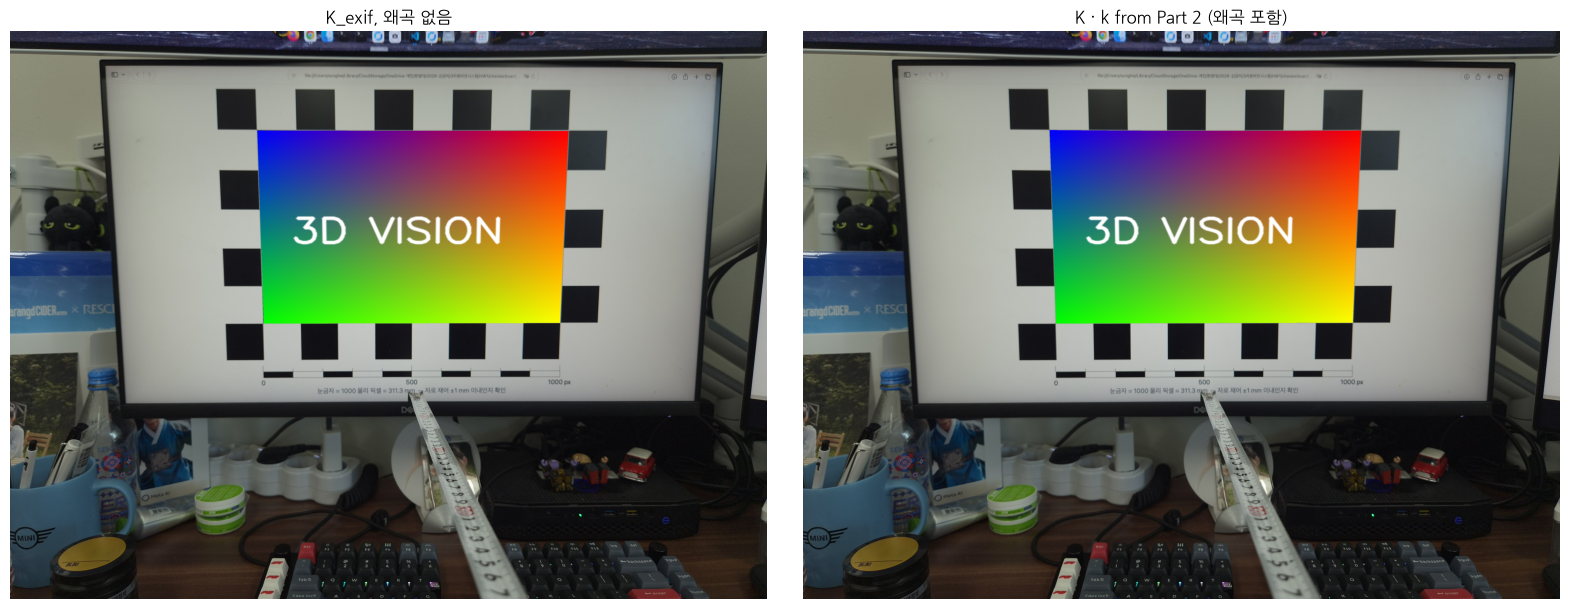

In [11]:
import cv2
img = E.load_image(os.path.join(DATA, 'setC', det['names'][i]), scale=det['scale'])[:, :, ::-1]
tex_path = os.path.join(DATA, 'texture.png')
tex = E.load_image(tex_path)[:, :, ::-1] if os.path.exists(tex_path) else np.repeat((np.indices((120, 160)).sum(0) % 2 * 255).astype(np.uint8)[..., None], 3, axis=2)
extent = ((det['pattern'][0] - 1) * det['square'], (det['pattern'][1] - 1) * det['square'])
identity = lambda xd, yd: (xd, yd)
out_nodist = warp_texture_onto_board(img, tex, K_exif, R, t, identity, extent)
try:
    K_z, kinfo = IO.load_K('K.json'); dist_z, _ = IO.load_dist('dist.json')
    K_z = IO.rescale_K_for_image(K_z, kinfo['image_size'], det['image_size'])
    # H = K[r1 r2 t]는 왜곡 없는 픽셀 평면의 관계이므로, 코너부터 역왜곡하여 다시 추정.
    m_ideal = cv2.undistortPoints(m.reshape(-1, 1, 2), K_z, dist_z, P=K_z).reshape(-1, 2)
    H_ideal, _ = cv2.findHomography(X[:, :2], m_ideal)
    Rz, tz = decompose_board_homography(K_z, H_ideal)
    def undist_cv(xd, yd):          # 1.4 에서는 cv2.undistortPoints 허용 (직접 구현은 Part 5)
        pts = np.column_stack([xd.ravel(), yd.ravel()]).astype(np.float64).reshape(-1, 1, 2)
        u = cv2.undistortPoints(pts, np.eye(3), dist_z).reshape(-1, 2)
        return u[:, 0].reshape(xd.shape), u[:, 1].reshape(xd.shape)
    out_dist = warp_texture_onto_board(img, tex, K_z, Rz, tz, undist_cv, extent)
    title2 = 'K · k from Part 2 (왜곡 포함)'
except FileNotFoundError:
    out_dist = out_nodist; title2 = '(Part 2 뒤에 다시 실행)'
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].imshow(out_nodist); ax[0].set_title('K_exif, 왜곡 없음'); ax[1].imshow(out_dist); ax[1].set_title(title2)
for a in ax: a.set_axis_off()
fig.tight_layout(); fig.savefig(IO.rpath('part1_insert.png'), dpi=110, bbox_inches='tight')

## 보고서에 넣을 것 (Part 1, 슬라이드 3장)
1. f 예측표(규약별 값, 택한 값과 이유) + 오차 요인 셋
2. 거리 비교(추정 vs 실측, 오차 %) + 1.3 변환 규칙 식과 검증표(예측 vs 재캘리브레이션, σ 와 비교)
3. 삽입 결과 2장(왜곡 미포함/포함) — 보드 모서리 확대 비교 한 컷

In [12]:
CK.run_all(globals());

  [OK]   K 변환 규칙 — 축소 오차 0.000, 크롭 오차 0.000, 회전 오차 0.000 (1 px 이내 허용: 규약 차이)
  [OK]   H = K[r1 r2 t] 분해 — R 오차 3.33e-16, t 오차 1.14e-13 mm
